/tmp/ipykernel_2428824/3646496026.py:175: DtypeWarning: Columns (0,7) have mixed types. Specify dtype option on import or set low_memory=False.
  test = pd.read_csv("/home/s1856122/dataset/KIBA/KIBA_SPECTRA_VSDS_10_50_from_merged_remove_overlap_data_t0.80_cleavage_spectra_seen_target_mol_deepcoy_augment.csv")


Molecular features shape: (1116949, 466)
Kinase features shape: (1116950, 200)

Total unique UniProt IDs: 172

EVALUATING FOLD 1
Loaded model: /home/s1856122/KinSEPC_upload/github/model/KinSPEC_MCA_training_band_10_50_fold1.json

Fold 1 Overall Metrics:
  ROC-AUC = 0.7936
  PR-AUC = 0.2320
  BEDROC = 0.3961
  EF_0.5% = 13.0520
  EF_1.0% = 10.8828
  EF_2.0% = 8.9301

EVALUATING FOLD 2
Loaded model: /home/s1856122/KinSEPC_upload/github/model/KinSPEC_MCA_training_band_10_50_fold2.json

Fold 2 Overall Metrics:
  ROC-AUC = 0.7907
  PR-AUC = 0.2306
  BEDROC = 0.3960
  EF_0.5% = 13.0776
  EF_1.0% = 10.9127
  EF_2.0% = 8.9056

EVALUATING FOLD 3
Loaded model: /home/s1856122/KinSEPC_upload/github/model/KinSPEC_MCA_training_band_10_50_fold3.json

Fold 3 Overall Metrics:
  ROC-AUC = 0.7908
  PR-AUC = 0.2355
  BEDROC = 0.4033
  EF_0.5% = 13.5476
  EF_1.0% = 11.2096
  EF_2.0% = 9.0391

EVALUATING FOLD 4
Loaded model: /home/s1856122/KinSEPC_upload/github/model/KinSPEC_MCA_training_band_10_50_fold4.js

/tmp/ipykernel_2428824/3646496026.py:361: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([ef_2_mean_list], labels=["EF 2% (Mean)"])
/tmp/ipykernel_2428824/3646496026.py:371: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([ef_5_mean_list], labels=["EF 5% (Mean)"])
/tmp/ipykernel_2428824/3646496026.py:380: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([ef_10_mean_list], labels=["EF 10% (Mean)"])


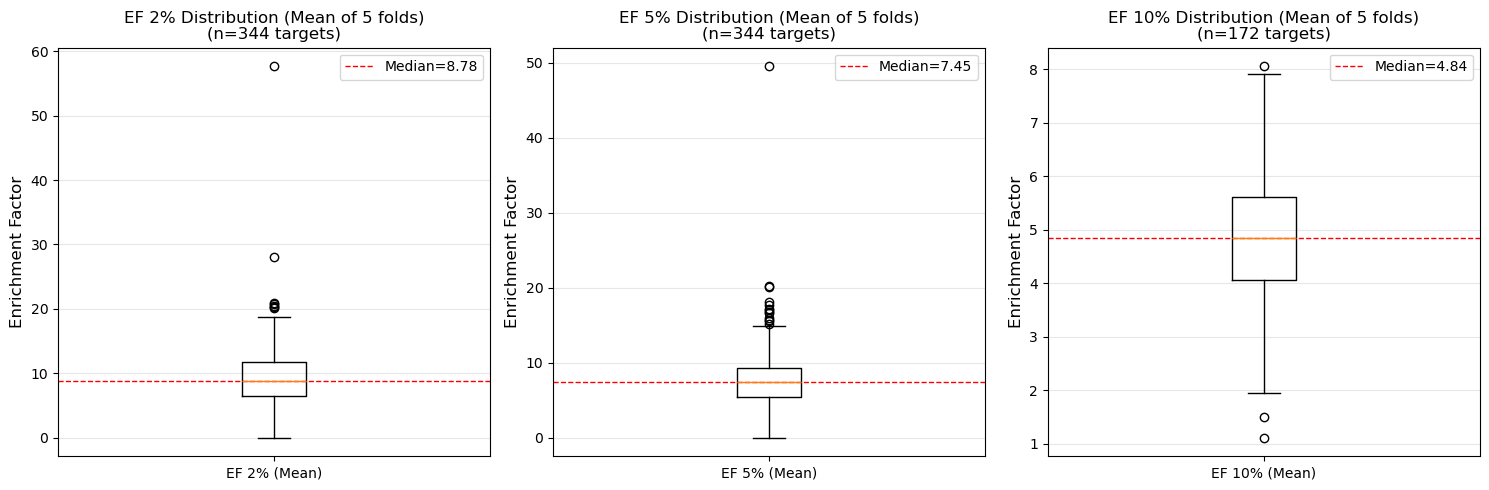


Boxplot saved to: ./KIBA_from_merged_seen_target_deepcoy_augment/ef_boxplot_5folds_mean.png

PER-TARGET EF STATISTICS (Mean of 5 folds)

EF 2%:
  Count: 344
  Mean: 9.2315
  Median: 8.7823
  Std: 5.0554
  Min: 0.0000
  Max: 57.6485
  Q1 (25%): 6.4797
  Q3 (75%): 11.7121

EF 5%:
  Count: 344
  Mean: 7.8106
  Median: 7.4463
  Std: 4.1025
  Min: 0.0000
  Max: 49.5441
  Q1 (25%): 5.4163
  Q3 (75%): 9.2948

EF 10%:
  Count: 172
  Mean: 4.8399
  Median: 4.8446
  Std: 1.1822
  Min: 1.1170
  Max: 8.0521
  Q1 (25%): 4.0550
  Q3 (75%): 5.6031

Overall metrics for all folds saved to: ./KIBA_from_merged_seen_target_deepcoy_augment/xgb_eval_overall_all_folds.csv
Overall metrics summary (mean±std) saved to: ./KIBA_from_merged_seen_target_deepcoy_augment/xgb_eval_overall_summary.csv
Per-target mean metrics saved to: ./KIBA_from_merged_seen_target_deepcoy_augment/xgb_eval_per_target_mean.csv

EVALUATION COMPLETE


In [ ]:
import pandas as pd
import xgboost as xgb
import numpy as np
from sklearn.metrics import precision_recall_curve,log_loss,accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,matthews_corrcoef,roc_auc_score
from scipy.stats import norm
from collections import Counter
from scipy.stats import norm
import matplotlib.pyplot as plt

# Bin bioactivity values
def bio_cal(bioactivity):
    # PKIS1 contains values above 100 and below 0, so bin the values
    bioactivity = bioactivity.clip(0,100)
    # Binning rule: define fixed intervals and their corresponding labels
    bins = [-np.inf, 50, np.inf]  # Left-closed, right-open intervals for classifying logit-normalized data
    labels = [0, 1]  # Bin labels: normalized activity intensity
    
    final_bioactivity = pd.cut(
    bioactivity, 
    bins=bins, 
    labels=labels, 
    include_lowest=True
    )
    return final_bioactivity

def klifs_map(df,KLIFS_file,KLIFS_latent): # df is the data to transform; KLIFS_file contains all KLIFS data; KLIFS_latent contains the corresponding reduced representations
    # Read KLIFS data from the cold file
    read_klifs = df['KLIFS'].astype(str).str.strip()
    # Read KLIFS data from the KLIFS dataset
    KLIFS = KLIFS_file['KLIFS'].astype(str).str.strip()
    # Map KLIFS sequences to their reduced representations and create a dictionary
    keys = KLIFS
    values = KLIFS_latent
    KLIFS_dict = dict(zip(keys,values))
    # Apply the mapping
    kinase_result = [KLIFS_dict.get(x.lstrip(),None) for x in read_klifs]
    return kinase_result

def dataset(input_feature, bioactivity):
    # Process labels
    input_feature.columns = range(input_feature.shape[1])
    # Sanity check
    assert len(input_feature) == len(bioactivity), "Input features and bioactivity lengths do not match!"
    # Build the DMatrix
    Xy = xgb.DMatrix(input_feature, label=bioactivity)
    return Xy,input_feature,bioactivity

def calculate_bedroc(y_true, y_score, bedroc_alpha):
    y_true  = np.asarray(y_true)
    y_score = np.asarray(y_score)
    N = len(y_true)
    n_act = np.sum(y_true == 1)
    if n_act == 0:
        return 0.0                    # Return 0 when there are no active compounds

    # 1. Sort and obtain the ranks of active compounds
    order  = np.argsort(y_score)[::-1]
    ranks  = np.arange(1, N+1)[y_true[order] == 1]      # 1-based
    x      = (ranks - 0.5) / N                          # Centered ranks

    # 2. Calculate RIE
    C      = (1.0 - np.exp(-bedroc_alpha)) / bedroc_alpha
    rie    = np.mean(np.exp(-bedroc_alpha * x)) / C

    # 3. Calculate the limiting values
    x_max  = (np.arange(1, n_act+1) - 0.5) / N          # Best case
    x_min  = (np.arange(N-n_act+1, N+1) - 0.5) / N      # Worst case
    rie_max = np.mean(np.exp(-bedroc_alpha * x_max)) / C
    rie_min = np.mean(np.exp(-bedroc_alpha * x_min)) / C

    # 4. Normalize
    return (rie - rie_min) / (rie_max - rie_min)

def calculate_ef(y_true, y_score, percentages=[0.5, 1.0, 2.0, 3.0, 4.0, 5.0], verbose=True):

    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    
    # Validate inputs
    if len(y_true) != len(y_score):
        raise ValueError("y_true and y_score must have the same length")
    
    N = len(y_true)  # Total number of compounds
    n_active = np.sum(y_true == 1)  # Total number of active compounds
    
    if n_active == 0:
        if verbose:
            print("Warning: no active compounds; returning EF=0")
        return {f"EF_{p}%": 0.0 for p in percentages}
    
    # Sort by predicted score in descending order
    sorted_indices = np.argsort(y_score)[::-1]
    sorted_labels = y_true[sorted_indices]
    
    results = {}
    
    for percentage in percentages:
        # Calculate the number of compounds in the top x%
        n_selected = max(1, int(N * percentage / 100))  # Select at least one compound
        
        # Number of active compounds in the top x%
        n_active_in_selected = np.sum(sorted_labels[:n_selected])
        
        # Calculate the enrichment factor
        # EF = (fraction of active compounds in the top x%) / (fraction of active compounds in the full dataset)
        ef_value = (n_active_in_selected / n_selected) / (n_active / N)
        
        results[f"EF_{percentage}%"] = ef_value
        
        if verbose:
            # Print detailed information
            print(f"EF_{percentage}%:")
            print(f"  - Selected compounds: {n_selected}/{N} ({percentage}%)")
            print(f"  - Active compounds among selected: {n_active_in_selected}")
            print(f"  - Active-compound fraction: {n_active_in_selected/n_selected:.4f}")
            print(f"  - Overall dataset active fraction: {n_active/N:.4f}")
            print(f"  - EF value: {ef_value:.4f}")
            print()
    
    return results

# ========= Helper: safely calculate ROC-AUC / PR-AUC (return NaN for a single class) =========
def safe_roc_auc(y_true, y_score):
    y_true = np.asarray(y_true).astype(int)
    if len(np.unique(y_true)) < 2:
        return np.nan
    return float(roc_auc_score(y_true, y_score))

def safe_pr_auc(y_true, y_score):
    from sklearn.metrics import auc
    y_true = np.asarray(y_true).astype(int)
    if len(np.unique(y_true)) < 2:
        return np.nan
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    return float(auc(recall, precision))

def fmt4(x):
    return "NaN" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:.4f}"

# ========= Evaluation function: accept a row mask and return a set of metrics =========
def eval_subset(mask, model, test_input_feature, test_bio, name="SUBSET", ef_percents=(0.5, 1.0, 2.0)):
    X_sub = test_input_feature[mask].copy()
    y_sub = np.asarray(test_bio[mask]).astype(int)
    
    dsub = xgb.DMatrix(X_sub, label=y_sub)
    s_sub = model.predict(dsub)
    
    out = {}
    out["N"] = int(len(y_sub))
    out["Actives"] = int(np.sum(y_sub == 1))
    out["ActiveRatio"] = float(out["Actives"] / out["N"]) if out["N"] > 0 else np.nan
    
    out["ROC_AUC"] = safe_roc_auc(y_sub, s_sub)
    out["PR_AUC"] = safe_pr_auc(y_sub, s_sub)
    out["BEDROC"] = calculate_bedroc(y_sub, s_sub, bedroc_alpha=80.5)
    
    ef_dict = calculate_ef(y_sub, s_sub, percentages=ef_percents, verbose=False)
    out.update(ef_dict)
    
    return out

# ========= Load test data =========
test_mol_fp = pd.read_csv("../dataset/KIBA_10_50_from_merged_seen_target_mol_deepcoy_augment_LSAE_latent_top95_features_2.csv",skiprows=1,header=None)
test = pd.read_csv("../dataset/KIBA_SPECTRA_VSDS_10_50_from_merged_remove_overlap_data_t0.80_cleavage_spectra_seen_target_mol_deepcoy_augment.csv")
test_klifs = test['KLIFS']
test['Label'] = (test['KIBA'] < 3).astype(int)
test_bio = test['Label']

KLIFS_sae_top = pd.read_csv("../feature_embedding/Kinase_test_MCA/MCA_klifs_482_200D_features.csv",skiprows=1, header=None).values
KLIFS_file = pd.read_csv("../feature_embedding/Kinase_test_MCA/human_482_typical_kinase_1955bit.csv")

output_path = './KIBA_from_merged_seen_target_deepcoy_augment'

test_kinase_fp = pd.DataFrame(klifs_map(test,KLIFS_file,KLIFS_sae_top))
test_input_feature = pd.concat([test_mol_fp,test_kinase_fp],axis=1)
test_input_feature.columns = range(test_input_feature.shape[1])

print("Molecular features shape:", test_mol_fp.shape)
print("Kinase features shape:", test_kinase_fp.shape)

test_input_feature = test_input_feature.reset_index(drop=True)
test = test.reset_index(drop=True)
test_bio = test_bio.reset_index(drop=True)

# ========= Read uniprot_id =========
if "uniprot_id" not in test.columns:
    raise ValueError(f"CSV missing 'uniprot_id'. Available columns: {list(test.columns)}")

uniprot_ids = test["uniprot_id"].astype(str).values

if len(uniprot_ids) != len(test_input_feature):
    raise ValueError(
        f"Row mismatch: uniprot_csv has {len(uniprot_ids)} rows, "
        f"but test_input_feature has {len(test_input_feature)} rows."
    )

unique_uniprots = np.unique(uniprot_ids)
print(f"\nTotal unique UniProt IDs: {len(unique_uniprots)}")

# ========= Load and evaluate each of the five fold models =========
n_folds = 5
model_base_path = "../model"

# Store overall metrics for each fold
overall_metrics_all_folds = []

# Store per-target metrics for each fold
per_target_all_folds = {uniprot: [] for uniprot in unique_uniprots}

for fold in range(1, n_folds + 1):
    print(f"\n{'='*80}")
    print(f"EVALUATING FOLD {fold}")
    print("="*80)
    
    # Load the model
    model_path = f"{model_base_path}/KinSPEC_MCA_training_band_10_50_fold{fold}.json"
    model = xgb.Booster()
    model.load_model(model_path)
    print(f"Loaded model: {model_path}")
    
    # ========= 1) Calculate overall metrics =========
    X_all = test_input_feature.copy()
    y_all = np.asarray(test_bio).astype(int)
    dall = xgb.DMatrix(X_all, label=y_all)
    s_all = model.predict(dall)
    
    N_all = len(y_all)
    Actives_all = int(np.sum(y_all == 1))
    ActiveRatio_all = Actives_all / N_all
    
    roc_auc_all = safe_roc_auc(y_all, s_all)
    pr_auc_all = safe_pr_auc(y_all, s_all)
    bedroc_all = calculate_bedroc(y_all, s_all, bedroc_alpha=80.5)
    ef_all = calculate_ef(y_all, s_all, percentages=(0.5, 1.0, 2.0), verbose=False)
    
    overall_metrics_all_folds.append({
        'Fold': fold,
        'N': N_all,
        'Actives': Actives_all,
        'Active_Ratio': ActiveRatio_all,
        'ROC_AUC': roc_auc_all,
        'PR_AUC': pr_auc_all,
        'BEDROC': bedroc_all,
        'EF_0.5%': ef_all.get('EF_0.5%'),
        'EF_1.0%': ef_all.get('EF_1.0%'),
        'EF_2.0%': ef_all.get('EF_2.0%')
    })
    
    print(f"\nFold {fold} Overall Metrics:")
    print(f"  ROC-AUC = {fmt4(roc_auc_all)}")
    print(f"  PR-AUC = {fmt4(pr_auc_all)}")
    print(f"  BEDROC = {fmt4(bedroc_all)}")
    print(f"  EF_0.5% = {fmt4(ef_all.get('EF_0.5%'))}")
    print(f"  EF_1.0% = {fmt4(ef_all.get('EF_1.0%'))}")
    print(f"  EF_2.0% = {fmt4(ef_all.get('EF_2.0%'))}")
    
    # ========= 2) Evaluate each UniProt separately =========
    for uniprot in unique_uniprots:
        mask_t = (uniprot_ids == uniprot)
        n_samples = np.sum(mask_t)
        
        # Process only targets with at least 10 samples
        if n_samples < 10:
            continue
        
        metrics = eval_subset(mask_t, model, test_input_feature, test_bio, 
                            name=f"TARGET {uniprot}", ef_percents=(0.5, 1, 2, 5, 10))
        metrics["Fold"] = fold
        metrics["Target"] = uniprot
        
        per_target_all_folds[uniprot].append(metrics)

# ========= 3) Calculate the mean and standard deviation across five folds =========
print(f"\n{'='*80}")
print("CALCULATING AVERAGE AND STD ACROSS 5 FOLDS")
print("="*80)

# Mean and standard deviation of overall metrics
overall_df = pd.DataFrame(overall_metrics_all_folds)
overall_mean = overall_df.drop('Fold', axis=1).mean()
overall_std = overall_df.drop('Fold', axis=1).std()

print("\nOVERALL METRICS (Mean ± Std across 5 folds):")
print(f"  ROC-AUC = {overall_mean['ROC_AUC']:.4f} ± {overall_std['ROC_AUC']:.4f}")
print(f"  PR-AUC = {overall_mean['PR_AUC']:.4f} ± {overall_std['PR_AUC']:.4f}")
print(f"  BEDROC = {overall_mean['BEDROC']:.4f} ± {overall_std['BEDROC']:.4f}")
print(f"  EF_0.5% = {overall_mean['EF_0.5%']:.4f} ± {overall_std['EF_0.5%']:.4f}")
print(f"  EF_1.0% = {overall_mean['EF_1.0%']:.4f} ± {overall_std['EF_1.0%']:.4f}")
print(f"  EF_2.0% = {overall_mean['EF_2.0%']:.4f} ± {overall_std['EF_2.0%']:.4f}")

# Mean per-target metrics
per_target_mean_list = []
ef_2_mean_list = []
ef_5_mean_list = []
ef_10_mean_list = []

for uniprot in unique_uniprots:
    if len(per_target_all_folds[uniprot]) == 0:
        continue
    
    # Convert to a DataFrame for easier calculation
    target_df = pd.DataFrame(per_target_all_folds[uniprot])
    
    # Calculate the mean
    target_mean = {
        'Target': uniprot,
        'N': int(target_df['N'].mean()),
        'Actives': int(target_df['Actives'].mean()),
        'ActiveRatio': target_df['ActiveRatio'].mean(),
        'ROC_AUC_mean': target_df['ROC_AUC'].mean(),
        'ROC_AUC_std': target_df['ROC_AUC'].std(),
        'PR_AUC_mean': target_df['PR_AUC'].mean(),
        'PR_AUC_std': target_df['PR_AUC'].std(),
        'BEDROC_mean': target_df['BEDROC'].mean(),
        'BEDROC_std': target_df['BEDROC'].std(),
        'EF_0.5%_mean': target_df['EF_0.5%'].mean(),
        'EF_0.5%_std': target_df['EF_0.5%'].std(),
        'EF_1%_mean': target_df['EF_1%'].mean(),
        'EF_1%_std': target_df['EF_1%'].std(),
        'EF_2%_mean': target_df['EF_2%'].mean(),
        'EF_2%_std': target_df['EF_2%'].std(),
        'EF_5%_mean': target_df['EF_5%'].mean(),
        'EF_5%_std': target_df['EF_5%'].std(),
        'EF_10%_mean': target_df['EF_10%'].mean(),
        'EF_10%_std': target_df['EF_10%'].std()
    }
    
    per_target_mean_list.append(target_mean)
    
    # Collect data for the box plot
    if not np.isnan(target_mean['EF_0.5%_mean']):
        ef_2_mean_list.append(target_mean['EF_0.5%_mean'])
    if not np.isnan(target_mean['EF_1%_mean']):
        ef_5_mean_list.append(target_mean['EF_1%_mean'])
    if not np.isnan(target_mean['EF_2%_mean']):
        ef_2_mean_list.append(target_mean['EF_2%_mean'])
    if not np.isnan(target_mean['EF_5%_mean']):
        ef_5_mean_list.append(target_mean['EF_5%_mean'])
    if not np.isnan(target_mean['EF_10%_mean']):
        ef_10_mean_list.append(target_mean['EF_10%_mean'])

# Convert to a DataFrame
per_target_mean_df = pd.DataFrame(per_target_mean_list)
print(f"\nProcessed {len(per_target_mean_df)} targets with >= 10 samples")

# ========= 4) Draw a box plot based on mean EF across five folds =========
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# EF 2% (mean across 5 folds)
axes[0].boxplot([ef_2_mean_list], labels=["EF 2% (Mean)"])
axes[0].set_ylabel("Enrichment Factor", fontsize=12)
axes[0].set_title(f"EF 2% Distribution (Mean of 5 folds)\n(n={len(ef_2_mean_list)} targets)", fontsize=12)
axes[0].grid(axis='y', alpha=0.3)
axes[0].axhline(y=np.median(ef_2_mean_list), color='r', linestyle='--', linewidth=1, 
                label=f'Median={np.median(ef_2_mean_list):.2f}')
axes[0].legend()


# EF 5% (mean across 5 folds)
axes[1].boxplot([ef_5_mean_list], labels=["EF 5% (Mean)"])
axes[1].set_ylabel("Enrichment Factor", fontsize=12)
axes[1].set_title(f"EF 5% Distribution (Mean of 5 folds)\n(n={len(ef_5_mean_list)} targets)", fontsize=12)
axes[1].grid(axis='y', alpha=0.3)
axes[1].axhline(y=np.median(ef_5_mean_list), color='r', linestyle='--', linewidth=1, 
                label=f'Median={np.median(ef_5_mean_list):.2f}')
axes[1].legend()

# EF 10% (mean across 5 folds)
axes[2].boxplot([ef_10_mean_list], labels=["EF 10% (Mean)"])
axes[2].set_ylabel("Enrichment Factor", fontsize=12)
axes[2].set_title(f"EF 10% Distribution (Mean of 5 folds)\n(n={len(ef_10_mean_list)} targets)", fontsize=12)
axes[2].grid(axis='y', alpha=0.3)
axes[2].axhline(y=np.median(ef_10_mean_list), color='r', linestyle='--', linewidth=1, 
                label=f'Median={np.median(ef_10_mean_list):.2f}')
axes[2].legend()

plt.tight_layout()
output_plot = f"{output_path}/ef_boxplot_5folds_mean.png"
plt.savefig(output_plot, dpi=300, bbox_inches='tight')
plt.show()
print(f"\nBoxplot saved to: {output_plot}")

# ========= 5) Print summary statistics for each EF =========
print("\n" + "="*60)
print("PER-TARGET EF STATISTICS (Mean of 5 folds)")
print("="*60)

for ef_name, ef_list in [("EF 2%", ef_2_mean_list), ("EF 5%", ef_5_mean_list), ("EF 10%", ef_10_mean_list)]:
    if len(ef_list) > 0:
        print(f"\n{ef_name}:")
        print(f"  Count: {len(ef_list)}")
        print(f"  Mean: {np.mean(ef_list):.4f}")
        print(f"  Median: {np.median(ef_list):.4f}")
        print(f"  Std: {np.std(ef_list):.4f}")
        print(f"  Min: {np.min(ef_list):.4f}")
        print(f"  Max: {np.max(ef_list):.4f}")
        print(f"  Q1 (25%): {np.percentile(ef_list, 25):.4f}")
        print(f"  Q3 (75%): {np.percentile(ef_list, 75):.4f}")

# ========= 6) Save results =========
# Save overall metrics for all five folds
out_overall_all_folds = f"{output_path}/xgb_eval_overall_all_folds.csv"
overall_df.to_csv(out_overall_all_folds, index=False)
print(f"\nOverall metrics for all folds saved to: {out_overall_all_folds}")

# Save the mean and standard deviation of overall metrics
overall_summary = pd.DataFrame({
    'Metric': ['ROC_AUC', 'PR_AUC', 'BEDROC', 'EF_0.5%', 'EF_1.0%', 'EF_2.0%'],
    'Mean': [overall_mean['ROC_AUC'], overall_mean['PR_AUC'], overall_mean['BEDROC'],
             overall_mean['EF_0.5%'], overall_mean['EF_1.0%'], overall_mean['EF_2.0%']],
    'Std': [overall_std['ROC_AUC'], overall_std['PR_AUC'], overall_std['BEDROC'],
            overall_std['EF_0.5%'], overall_std['EF_1.0%'], overall_std['EF_2.0%']]
})
out_overall_summary = f"{output_path}/xgb_eval_overall_summary.csv"
overall_summary.to_csv(out_overall_summary, index=False)
print(f"Overall metrics summary (mean±std) saved to: {out_overall_summary}")

# Save mean metrics for each target
out_per_target_mean = f"{output_path}/xgb_eval_per_target_mean.csv"
per_target_mean_df.to_csv(out_per_target_mean, index=False)
print(f"Per-target mean metrics saved to: {out_per_target_mean}")

print("\n" + "="*80)
print("EVALUATION COMPLETE")
print("="*80)